# Treinando um modelo de linguagem com os papers do arXiv

Mesma ideia da aula 7 (Irish lyrics): o modelo recebe uma sequência de palavras e prevê a próxima.
Depois usa isso pra gerar texto. Ele segue as seguintes etapas:

1. Carregar os `.md` e limpar
2. Dividir treino / validação / teste por paper
3. Tokenizar e montar as janelas (entrada -> próxima palavra)
4. Comparar arquiteturas (as das aulas 4 a 7)
5. Treinar a melhor
6. Avaliar no teste e gerar texto
7. Salvar modelo e tokenizer (o notebook 3 usa)

In [3]:
!pip install tensorflow pandas matplotlib

  Using cached tensorflow-2.21.0-cp312-cp312-manylinux_2_27_x86_64.whl.metadata (4.4 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.1-cp312-cp312-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (7.6 kB)
  Using cached grpcio-1.84.0-

In [4]:
import glob
import json
import os
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Input, Embedding, LSTM, GRU, Dense, Bidirectional, GlobalAveragePooling1D
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1792015866.854454  325201 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792015866.951342  325201 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792015869.290891  325201 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [5]:
SEED = 42
VOCAB = 8000 # só as 8000 palavras mais frequentes; o resto vira <OOV>
SEQ_LEN = 20 # quantas palavras o modelo "lê" pra prever a próxima
MAX_JANELAS_TREINO = 300000 # limite de exemplos de treino (acelera o treino)
EPOCAS_COMPARACAO = 5 # épocas de cada arquitetura na comparação
EPOCAS_FINAL = 30 # máximo de épocas do treino final (tem early stopping)
BATCH = 256

np.random.seed(SEED)
tf.random.set_seed(SEED)

## Carregando e limpando os `.md`

O Docling deixa bastante lixo: marcadores de imagem/fórmula, tabelas, símbolos de markdown e a lista de
referências no final. Tudo isso só atrapalharia o modelo, então a função abaixo tira.

In [6]:
def limpar(texto):
    # corta tudo a partir do título "References"/"Bibliography" (pega a última ocorrência)
    achados = list(re.finditer(r"\n#+\s*(references|bibliography)\b", texto, flags=re.I))
    if achados:
        texto = texto[:achados[-1].start()]

    texto = re.sub(r"<!--.*?-->", " ", texto, flags=re.S) # <!-- image -->, <!-- formula-not-decoded -->
    texto = re.sub(r"^\s*\|.*$", " ", texto, flags=re.M) # linhas de tabela
    texto = re.sub(r"https?://\S+", " ", texto) # links
    texto = re.sub(r"\[\d+(?:[,\u2013-]\s*\d+)*\]", " ", texto) # citações tipo [12] ou [3, 4]
    texto = re.sub(r"[#*_>`~\[\]()|]", " ", texto) # símbolos de markdown
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9.,;:'\- \n]", " ", texto) # fica só com letras, números e pontuação simples
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()


arquivos = sorted(glob.glob("data/markdown/*.md"))
textos = {}
for caminho in arquivos:
    t = limpar(open(caminho, encoding="utf-8").read())
    # descarta papers que sobraram vazios/curtos demais (conversão ruim)
    if len(t.split()) >= 500:
        textos[os.path.basename(caminho)] = t

print(len(arquivos), "arquivos |", len(textos), "usados")
print("total de palavras:", sum(len(t.split()) for t in textos.values()))

49 arquivos | 49 usados
total de palavras: 262216


In [7]:
# amostra do texto limpo
nome = list(textos)[0]
print(nome)
print(textos[nome][:600])

2610.04824v1.md
agent behavior as code: efficient and robust llm agents with programmatic specifications peng qi, chunliang lyu, gang li , fabian chan, cheng chang, ignacio cases , will lu uniphore abstract ai agents based on foundation models fms have demonstrated strong capabilities to perform complex open-ended tasks. however, they face some common challenges in practice: a agent behavior can deviate drastically even for semantically similar tasks, leading to catastrophically propagated errors; b high cost and latency due to fm calls, repeated in full whenever a task recurs with different inputs; c fms' li


## Treino / validação / teste por paper

Se a divisão fosse por janela, trechos vizinhos do mesmo paper cairiam em treino e validação e o modelo
"decoraria" o texto: a métrica ficaria bonita e falsa. Dividindo por paper, o teste é texto que ele nunca viu.

In [8]:
nomes = sorted(textos)
rng = np.random.default_rng(SEED)
rng.shuffle(nomes)

n = len(nomes)
n_teste = max(1, round(n * 0.1))
n_val = max(1, round(n * 0.1))

nomes_teste = nomes[:n_teste]
nomes_val = nomes[n_teste:n_teste + n_val]
nomes_treino = nomes[n_teste + n_val:]

print("treino:", len(nomes_treino), "| validação:", len(nomes_val), "| teste:", len(nomes_teste))

treino: 39 | validação: 5 | teste: 5


## Tokenização e janelas

Igual na aula, o `Tokenizer` transforma palavra em inteiro. Tem duas diferenças em relação ao notebook da aula:

- o tokenizer é ajustado só no treino, senão o teste "vaza" no vocabulário, e tem `num_words` +
  `oov_token` (aula 2 e 3), porque com texto de paper o vocabulário passa fácil de 50 mil palavras;
- em vez de n-gramas com `pad_sequences`, usa janelas deslizantes de tamanho fixo: as `SEQ_LEN`
  palavras anteriores são a entrada e a próxima é o alvo. Com texto longo isso evita milhões de zeros de padding.

In [9]:
tokenizer = Tokenizer(num_words=VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts([textos[x] for x in nomes_treino])

print("palavras distintas no treino:", len(tokenizer.word_index))
print("primeiras:", list(tokenizer.word_index.items())[:10])

palavras distintas no treino: 11704
primeiras: [('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('in', 7), ('is', 8), ('for', 9), ('with', 10)]


In [10]:
def fazer_janelas(nomes_papers, maximo=None):
    entradas, alvos = [], []
    for nome in nomes_papers:
        ids = tokenizer.texts_to_sequences([textos[nome]])[0]
        if len(ids) <= SEQ_LEN:
            continue
        ids = np.array(ids, dtype="int32")
        # todas as janelas de SEQ_LEN+1 palavras (as SEQ_LEN primeiras = entrada, a última = alvo)
        janelas = np.lib.stride_tricks.sliding_window_view(ids, SEQ_LEN + 1)
        entradas.append(janelas[:, :-1])
        alvos.append(janelas[:, -1])
    xs = np.concatenate(entradas)
    ys = np.concatenate(alvos)
    if maximo is not None and len(xs) > maximo:
        escolhidos = rng.choice(len(xs), maximo, replace=False)
        xs, ys = xs[escolhidos], ys[escolhidos]
    return xs, ys


x_treino, y_treino = fazer_janelas(nomes_treino, MAX_JANELAS_TREINO)
x_val, y_val = fazer_janelas(nomes_val, 50000)
x_teste, y_teste = fazer_janelas(nomes_teste, 50000)

print("treino:", x_treino.shape, "| val:", x_val.shape, "| teste:", x_teste.shape)

treino: (213533, 20) | val: (30350, 20) | teste: (26680, 20)


In [11]:
# um exemplo: as palavras de entrada e a que o modelo deve prever
inverso = {i: p for p, i in tokenizer.word_index.items()}
print(" ".join(inverso.get(i, "?") for i in x_treino[0]), "->", inverso.get(y_treino[0], "?"))

scopesae model scope feature discovery with interpretable layer selection qingwen zeng1 zehao fu1 shuyu meng1 linghan huang1 jiayi zhang2 chenglin -> wu3


## Comparando arquiteturas

Todas as arquiteturas vistas nas aulas, com o mesmo split, as mesmas épocas e o mesmo otimizador:

| nome | origem |
|---|---|
| `embedding_media` | aula 4: Embedding + média dos vetores (não tem noção de ordem; serve de baseline) |
| `lstm` | aula 5/6: uma LSTM |
| `bilstm` | aula 6/7: LSTM bidirecional (a da aula 7) |
| `lstm_empilhada` | aula 6: duas LSTMs empilhadas (`return_sequences=True` na primeira) |
| `gru` | variação mais leve da LSTM |

Diferença pra aula 7: usei `sparse_categorical_crossentropy`. O alvo fica como inteiro em vez de one-hot
(`to_categorical`), que com 8000 palavras × centenas de milhares de exemplos estouraria a memória.
Mesma matemática, só não precisa do vetor gigante.

In [12]:
def criar_modelo(tipo):
    modelo = Sequential()
    modelo.add(Input(shape=(SEQ_LEN,)))
    modelo.add(Embedding(VOCAB, 100))

    if tipo == "embedding_media":
        modelo.add(GlobalAveragePooling1D())
        modelo.add(Dense(128, activation="relu"))
    elif tipo == "lstm":
        modelo.add(LSTM(150))
    elif tipo == "bilstm":
        modelo.add(Bidirectional(LSTM(150)))
    elif tipo == "lstm_empilhada":
        modelo.add(LSTM(150, return_sequences=True))
        modelo.add(LSTM(150))
    elif tipo == "gru":
        modelo.add(GRU(150))

    # saída: probabilidade de cada palavra do vocabulário ser a próxima
    modelo.add(Dense(VOCAB, activation="softmax"))
    modelo.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(learning_rate=0.003),
        metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],
    )
    return modelo


criar_modelo("bilstm").summary()

E0000 00:00:1792015888.637980  325201 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 20, 100)        │       800,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 300)            │       301,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8000)           │     2,408,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,509,200 (13.39 MB)

 Trainable params: 3,509,200 (13.39 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
arquiteturas = ["embedding_media", "lstm", "bilstm", "lstm_empilhada", "gru"]
resultados = []
historicos = {}

for tipo in arquiteturas:
    print("\n=== %s ===" % tipo)
    modelo = criar_modelo(tipo)
    inicio = time.time()
    h = modelo.fit(
        x_treino, y_treino,
        validation_data=(x_val, y_val),
        epochs=EPOCAS_COMPARACAO, batch_size=BATCH, verbose=1,
    )
    historicos[tipo] = h.history

    # métricas da melhor época (menor val_loss)
    melhor = int(np.argmin(h.history["val_loss"]))
    resultados.append({
        "arquitetura": tipo,
        "parametros": modelo.count_params(),
        "tempo_s": round(time.time() - inicio),
        "val_loss": h.history["val_loss"][melhor],
        "perplexidade": float(np.exp(h.history["val_loss"][melhor])),
        "val_acc": h.history["val_accuracy"][melhor],
        "val_top5": h.history["val_top5"][melhor],
    })

tabela = pd.DataFrame(resultados).set_index("arquitetura").sort_values("val_loss")
tabela


=== embedding_media ===
Epoch 1/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 68s 80ms/step - accuracy: 0.0535 - loss: 7.1961 - top5: 0.1373 - val_accuracy: 0.0685 - val_loss: 6.7047 - val_top5: 0.1944
Epoch 2/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 67s 80ms/step - accuracy: 0.0614 - loss: 6.6894 - top5: 0.1518 - val_accuracy: 0.0734 - val_loss: 6.6923 - val_top5: 0.1948
Epoch 3/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 66s 79ms/step - accuracy: 0.0647 - loss: 6.2963 - top5: 0.1622 - val_accuracy: 0.0733 - val_loss: 6.7289 - val_top5: 0.1926
Epoch 4/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 67s 80ms/step - accuracy: 0.0676 - loss: 5.9736 - top5: 0.1749 - val_accuracy: 0.0711 - val_loss: 6.8268 - val_top5: 0.1865
Epoch 5/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 68s 82ms/step - accuracy: 0.0717 - loss: 5.6796 - top5: 0.1902 - val_accuracy: 0.0679 - val_loss: 6.9828 - val_top5: 0.1801

=== lstm ===
Epoch 1/5
835/835 ━━━━━━━━━━━━━━━━━━━━ 146s 172ms/step - accuracy: 0.0666 - loss: 7.0275 - top5: 0.1544 - val_accuracy: 0.1091 - val_loss: 6.4176 

,parametros,tempo_s,val_loss,perplexidade,val_acc,val_top5
arquitetura,,,,,,
gru,2121400,811,6.155904,471.492793,0.128534,0.260791
bilstm,3509200,5784,6.180918,483.435421,0.126326,0.255189
lstm,2158600,757,6.195033,490.307661,0.126161,0.253081
lstm_empilhada,2339200,1378,6.326477,559.183146,0.113476,0.241647
embedding_media,1844928,337,6.692286,806.163432,0.073377,0.194827


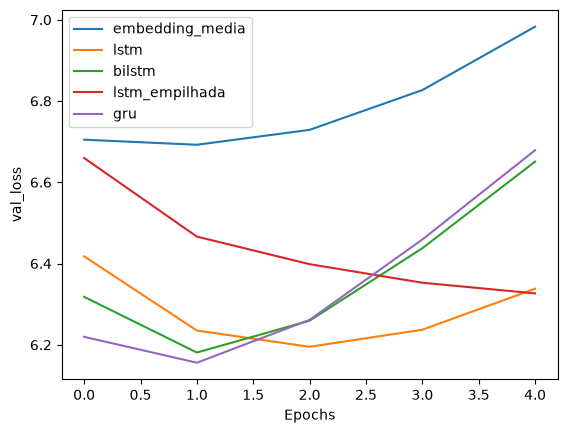

In [14]:
# val_loss de cada arquitetura ao longo das épocas
for tipo, h in historicos.items():
    plt.plot(h["val_loss"], label=tipo)
plt.xlabel("Epochs")
plt.ylabel("val_loss")
plt.legend()
plt.show()

In [15]:
# escolhe a de menor val_loss (a menor perplexidade) pro treino final
melhor_tipo = tabela.index[0]
print("escolhida:", melhor_tipo)

escolhida: gru


## Treino final

Treina a arquitetura escolhida por mais épocas. O `EarlyStopping` para quando a `val_loss` para de
melhorar e devolve os pesos da melhor época, assim o modelo não passa do ponto e começa a decorar
(overfitting), o que é comum com pouco texto.

In [16]:
modelo = criar_modelo(melhor_tipo)
parar = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = modelo.fit(
    x_treino, y_treino,
    validation_data=(x_val, y_val),
    epochs=EPOCAS_FINAL, batch_size=BATCH, callbacks=[parar], verbose=1,
)

Epoch 1/30
835/835 ━━━━━━━━━━━━━━━━━━━━ 158s 186ms/step - accuracy: 0.0741 - loss: 7.0692 - top5: 0.1657 - val_accuracy: 0.1193 - val_loss: 6.2748 - val_top5: 0.2473
Epoch 2/30
835/835 ━━━━━━━━━━━━━━━━━━━━ 180s 216ms/step - accuracy: 0.1276 - loss: 5.9661 - top5: 0.2510 - val_accuracy: 0.1261 - val_loss: 6.1721 - val_top5: 0.2573
Epoch 3/30
835/835 ━━━━━━━━━━━━━━━━━━━━ 155s 185ms/step - accuracy: 0.1672 - loss: 5.2206 - top5: 0.3200 - val_accuracy: 0.1248 - val_loss: 6.2666 - val_top5: 0.2561
Epoch 4/30
835/835 ━━━━━━━━━━━━━━━━━━━━ 150s 179ms/step - accuracy: 0.2031 - loss: 4.6504 - top5: 0.3809 - val_accuracy: 0.1206 - val_loss: 6.4451 - val_top5: 0.2501
Epoch 5/30
835/835 ━━━━━━━━━━━━━━━━━━━━ 162s 194ms/step - accuracy: 0.2407 - loss: 4.2020 - top5: 0.4382 - val_accuracy: 0.1135 - val_loss: 6.6561 - val_top5: 0.2397


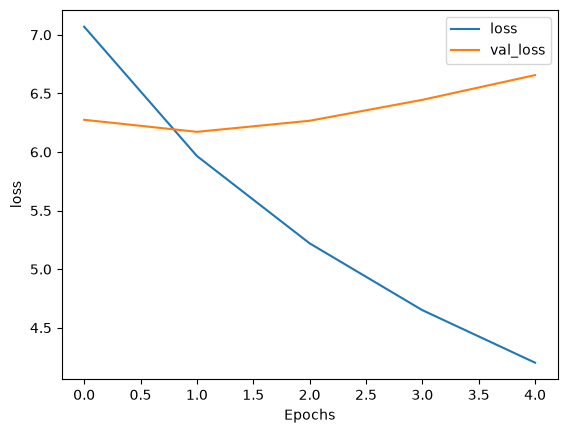

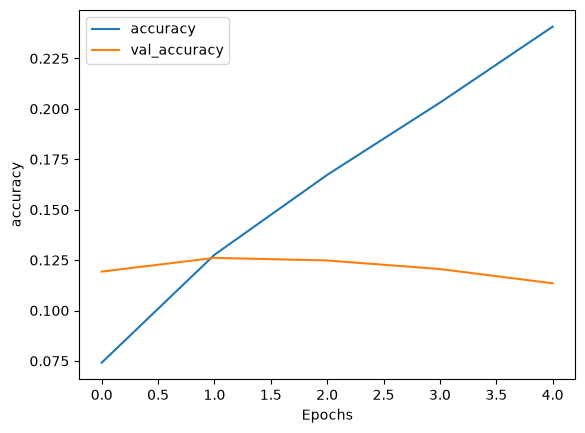

In [17]:
# mesma função de plot da aula
def plot_graphs(history, string):
    plt.plot(history.history[string])
    plt.plot(history.history["val_" + string])
    plt.xlabel("Epochs")
    plt.ylabel(string)
    plt.legend([string, "val_" + string])
    plt.show()


plot_graphs(history, "loss")
plot_graphs(history, "accuracy")

## Avaliação no teste

Papers que o modelo nunca viu, nem pra treinar nem pra escolher a arquitetura.
- **perplexidade** = `exp(loss)`: "entre quantas palavras o modelo está em dúvida". Quanto menor, melhor.
- **acurácia**: acertou exatamente a próxima palavra. **top-5**: a certa estava entre as 5 mais prováveis.

In [18]:
loss, acc, top5 = modelo.evaluate(x_teste, y_teste, batch_size=BATCH, verbose=0)
print("loss: %.3f | perplexidade: %.1f | acurácia: %.3f | top-5: %.3f" % (loss, np.exp(loss), acc, top5))

# referência: chutar sempre a palavra mais comum do treino
mais_comum = np.bincount(y_treino).argmax()
print("baseline (sempre a mais comum): %.3f" % np.mean(y_teste == mais_comum))

loss: 6.127 | perplexidade: 458.3 | acurácia: 0.122 | top-5: 0.263
baseline (sempre a mais comum): 0.056


### Gerando texto

A aula usa `argmax` (sempre a palavra mais provável), o que costuma travar em repetição. Aqui tem as
duas opções: `temperatura=0` faz o `argmax`; valores maiores (0.7 a 1.0) sorteiam a palavra de acordo
com a probabilidade, deixando o texto mais variado.

In [19]:
def gerar(seed_text, n_palavras=40, temperatura=0.8):
    texto = seed_text.lower()
    for _ in range(n_palavras):
        ids = tokenizer.texts_to_sequences([texto])[0]
        ids = pad_sequences([ids], maxlen=SEQ_LEN, padding="pre")
        probs = modelo.predict(ids, verbose=0)[0]

        if temperatura == 0:
            escolhida = int(np.argmax(probs))
        else:
            # reescala as probabilidades pela temperatura e sorteia
            p = np.log(probs + 1e-9) / temperatura
            p = np.exp(p - p.max())
            p /= p.sum()
            escolhida = int(np.random.choice(len(p), p=p))

        palavra = inverso.get(escolhida)
        # 0 (padding) e <OOV> não viram palavra
        if palavra is None or palavra == "<OOV>":
            continue
        texto += " " + palavra
    return texto


seed = "in this paper we propose"
for temp in [0, 0.7, 1.0]:
    print("temperatura", temp, "->", gerar(seed, 30, temp), "\n")

temperatura 0 -> in this paper we propose the two benchmarks and the two benchmarks and the highest model training and the original checkpoints in the original checkpoints in appendix c 3 4 4 4 3 3 2 

temperatura 0.7 -> in this paper we propose a novel t2i language model to the strongest study for the broader word and the fixed output token per work with the same stage 3 4 we compare the same 

temperatura 1.0 -> in this paper we propose transformer evidence and hi jaegle et al 2026 line et al 2024 jia et al 2025 wu et al 2026c claude realize recursive beyond ocr training is the exact 



## Salvando modelo e tokenizer

In [20]:
os.makedirs("data/modelo", exist_ok=True)

modelo.save("data/modelo/modelo_lm.keras")

# o tokenizer vira JSON (precisa dele pra transformar texto em número igual ao do treino)
with open("data/modelo/tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

# e os parâmetros que o notebook 3 precisa saber
with open("data/modelo/config.json", "w", encoding="utf-8") as f:
    json.dump({"seq_len": SEQ_LEN, "vocab": VOCAB, "arquitetura": melhor_tipo}, f)

tabela.to_csv("data/modelo/comparacao_arquiteturas.csv")
print(os.listdir("data/modelo"))

['config.json', 'modelo_lm.keras', 'comparacao_arquiteturas.csv', 'tokenizer.json']
